# **3**rd Experiment: Logistic Regression

### Goals

Set real baseline to get closer with a complex algorithm in the future (e.g, CNN). It'd a great start to get to know the features and decide what's usefull to the problem and what's just AI complexity. 

That's a method to isolate variables. Without `edge_index`, it's easier to focus on the power of my extracted variables.

### Challenges

Logistic Regression doesn't understand physical topology and needs a tradicional dataset (matrix/table).

It's necessary to redefine the instances. Instead of a whole graph with 31 nodes, each row in the table can represent a node in a especific time window.

The feature, for the beginning, will be normalized errows by the time windows. And the target will be leak or not leak.

### Stack

I will use `scikit-learn` to set the data, normalize features and train the model.

Also, this time I will use evaluation metrics to evaluate my study.

# Imports

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
import torch
import wntr

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from data_use import (
    normalizar_residuo, taxa_exceedance, calcular_residuo
)

from data_access import (
    get_all, leak_info
)

from data_menagement import (
    process_scenario_data
)

# Data preparation

In [2]:
def map_graph(scenarios):
    # carregar topologia
    wn = wntr.network.WaterNetworkModel(scenarios[118]['inp'])
    G = wn.to_graph().to_undirected()

    # lista em ordem fixa de nós
    list_nodes = sorted(wn.junction_name_list, key=int)
    nodes_index = {node: i for i, node in enumerate(list_nodes)} # enumerate devolve par (posição, valor) pra cada elemento de uma lista

    print(list_nodes)
    print(nodes_index)

    return G, list_nodes, nodes_index

In [3]:
# creating data

def build_scenario_data_table(item, list_nodes, janela_dias, window_size, step):
    list_data = []

    for n, item in item.items():
        dfs_nodes, leak_intervals, total_steps = process_scenario_data(item, list_nodes, janela_dias)

        for t_init in range(0, total_steps - window_size + 1, step):
            t_end = t_init + window_size

            for node in list_nodes:
                df_node = dfs_nodes[node]

                # extract slice from error_normalizado nessa window
                slice = df_node.loc[t_init:t_end, 'error_normalizado'].values

                # in case of wrong size
                if len(slice) < window_size:
                    continue

                is_leaking = False
                for leak_node, (start, end) in  leak_intervals.items():
                    # leakege is happening in this window and in this node?
                    if str(node) == str(leak_node) and not (t_end < start or t_init > end):
                        is_leaking = True
                        break
        
                row = {
                    'scenario': item['n_scenario'],
                    'node': node,
                    't_init': t_init,
                    'target': 1 if is_leaking else 0
                }

                # fiiling the tb
                for i, val in enumerate(slice):
                    row[f't_{i}'] = float(val)

                list_data.append(row)

    return pd.DataFrame(list_data)


# Training

In [4]:
scenarios = get_all("train")
    # path
    # inp
    # info
    # leaks
    # pressures

print(scenarios)

G, list_nodes, nodes_index = map_graph(scenarios)
df_dataset = build_scenario_data_table(scenarios, list_nodes, janela_dias=14, window_size=48, step=48)

{109: {'n_scenario': 109, 'path': 'C:\\Users\\Mirella Fontinelle\\Leakage Research\\data\\object\\train\\Scenario-109', 'inp': 'C:\\Users\\Mirella Fontinelle\\Leakage Research\\data\\object\\train\\Scenario-109\\Hanoi_CMH_Scenario-109.inp', 'info': 'C:\\Users\\Mirella Fontinelle\\Leakage Research\\data\\object\\train\\Scenario-109\\Scenario-109_info.csv', 'leaks': [11, 27], 'pressures': 'C:\\Users\\Mirella Fontinelle\\Leakage Research\\data\\object\\train\\Scenario-109\\Pressures'}, 118: {'n_scenario': 118, 'path': 'C:\\Users\\Mirella Fontinelle\\Leakage Research\\data\\object\\train\\Scenario-118', 'inp': 'C:\\Users\\Mirella Fontinelle\\Leakage Research\\data\\object\\train\\Scenario-118\\Hanoi_CMH_Scenario-118.inp', 'info': 'C:\\Users\\Mirella Fontinelle\\Leakage Research\\data\\object\\train\\Scenario-118\\Scenario-118_info.csv', 'leaks': [18], 'pressures': 'C:\\Users\\Mirella Fontinelle\\Leakage Research\\data\\object\\train\\Scenario-118\\Pressures'}, 146: {'n_scenario': 146, 'pat

In [5]:
X = df_dataset[[f"t_{i}" for i in range(48)]]
y = df_dataset['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1] # Probabilidade do modelo para a classe 1 (vazamento)

# Evaluate

A biblioteca organiza a matriz com base na ordem numérica ou alfabética das suas classes (0 e 1).

Como o 0 (Not leak) vem antes do 1 (Leak), o Scikit-Learn coloca obrigatoriamente a classe 0 na primeira linha e coluna, e a classe 1 na segunda.

#### Mapping

Linha 0, Coluna 0 (12259): **True Negative**.

Linha 0, Coluna 1 (7924): **False Positive**.

Linha 1, Coluna 0 (121): **False Negative**.

Linha 1, Coluna 1 (63): **True Positive**.

In [7]:
print("--- Confusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\n --- Classification Report --- ")
print(classification_report(y_test, y_pred, target_names=['Not leak (0)', 'Leak (1)']))

print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_prob): .4f}")

--- Confusion Matrix
[[12293  7890]
 [  121    63]]

 --- Classification Report --- 
              precision    recall  f1-score   support

Not leak (0)       0.99      0.61      0.75     20183
    Leak (1)       0.01      0.34      0.02       184

    accuracy                           0.61     20367
   macro avg       0.50      0.48      0.38     20367
weighted avg       0.98      0.61      0.75     20367


ROC-AUC Score:  0.4521


A análise isolada de janelas temporais com modelos lineares (baseline com Logistic Regression) gerou um ROC-AUC de apenas 0.45,que é pior que random guessing, o que prova a insuficiência da dependência temporal isolada.

Isso justifica a necessidade de incorporar a topologia física da rede através de métodos mais sofisticados.

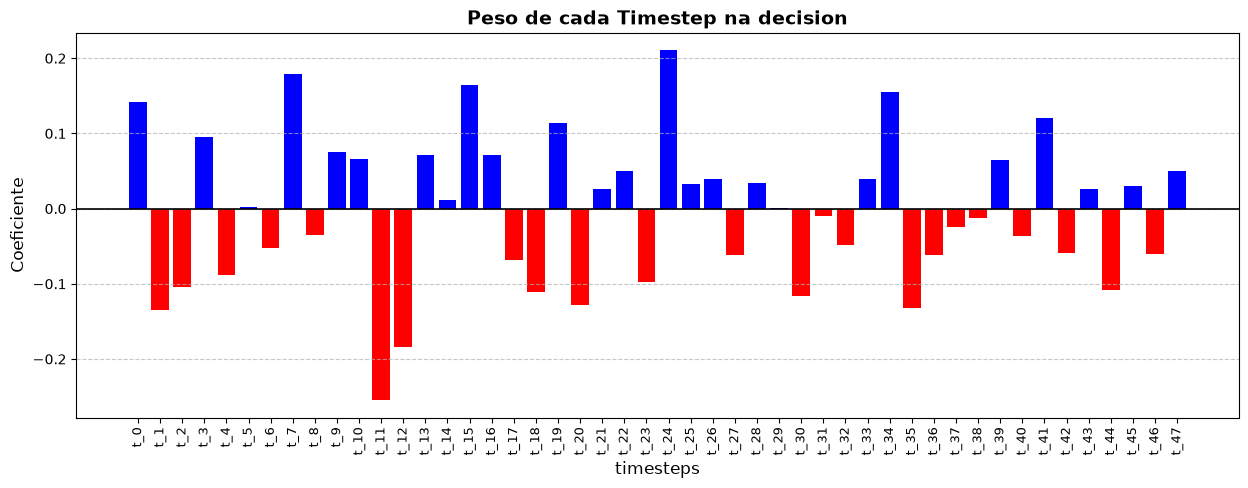

In [14]:
w = model.coef_[0]

timesteps = [f"t_{i}" for i in range(48)]

colors = ['blue' if p > 0 else 'red' for p in w]

plt.figure(figsize=(15, 5))
plt.bar(timesteps, w, color=colors)

plt.axhline(0, color='black', linewidth=1.2)
plt.title("Peso de cada Timestep na decision", fontsize=14, fontweight='bold')
plt.xlabel("timesteps", fontsize=12)
plt.ylabel("Coeficiente", fontsize=12)
plt.xticks(rotation=90, fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()



Esse tipo de situação em que os dados demonstram uma oscilação é o retrato de um modelo completamente confuso. As barras estão em um padrão de zig-zag, pois para a Logistic Regression não há continuidade temporal ou topologia.

Os timesteps não estão sendo absorvidos como sequência de tempo, mas apenas variáveis independentes para tentar somar e subtrair para encontrar um resultado melhor, então falhou completamente em capturar a continuidade temporal do vazamento, ou seja, uma queda de pressão contínua.

Sem conseguir assimilar o "formato de onda" ao longo das 48 horas, o modelo dá pesos aleatórios negativos e poitivos para tentar estabilizar.